# 07 · Segments, Explanations and Responsible AI
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

1. Segment profiling for campaign scripting and team allocation.
2. Global and local feature attribution (permutation importance and TreeSHAP).
3. Fairness and ethical audit across demographic attributes.

- **Input:** Tuned pipeline (notebook 04), `artifacts/policy_scores.npz` (notebook 06)

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import *
from src.data.prepare import load_modelling_data
from src.features.preprocessing import build_pipeline, add_features, CAT_COLS
from src.models.candidates import build_main_models
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train, X_test, y_test = data["X_train"], data["y_train"], data["X_test"], data["y_test"]
best_pipe = joblib.load(ARTIFACTS_DIR / "tuned_pipeline.joblib")
pol = np.load(ARTIFACTS_DIR / "policy_scores.npz")
s_raw, s_cal, budget_mask = pol["s_raw"], pol["s_cal"], pol["budget_mask"]
thr_theory = json.loads((ARTIFACTS_DIR / "policy_labels.json").read_text())["thr_theory"]
models = build_main_models()

Loading local file: bank-additional-full.csv
Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Customer Segmentation Analysis
Clustering client demographic attributes (age, job, marital status, education, default, housing, loan) to create operational tiers and guide campaign messaging.

In [2]:
CLIENT_CAT = ["job", "marital", "education", "default", "housing", "loan"]
seg_prep = ColumnTransformer([("n", StandardScaler(), ["age"]), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CLIENT_CAT)])
Z_train = seg_prep.fit_transform(X_train)
sample = np.random.RandomState(SEED).choice(len(Z_train), min(6000, len(Z_train)), replace=False)
sil = {}
for k in range(3, 8):
    km = KMeans(k, n_init=5, random_state=SEED).fit(Z_train)
    sil[k] = silhouette_score(Z_train[sample], km.labels_[sample])
best_k = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", best_k)

km = KMeans(best_k, n_init=10, random_state=SEED).fit(Z_train)
seg_test = km.predict(seg_prep.transform(X_test))
prof = []
for s in range(best_k):
    m = seg_test == s; sub = X_test[m]
    prof.append(dict(segment=s, clients_pct=100 * m.mean(), median_age=sub["age"].median(), top_job=sub["job"].mode().iat[0],
                     pct_housing_loan=100 * (sub["housing"] == "yes").mean(), pct_university=100 * (sub["education"] == "university.degree").mean(),
                     actual_response_pct=100 * y_test[m].mean(), mean_model_score_pct=100 * s_cal[m].mean(), pct_in_budget_list=100 * budget_mask[m].mean()))
seg_profile = pd.DataFrame(prof).set_index("segment").sort_values("mean_model_score_pct", ascending=False).round(1)
seg_profile["call_priority"] = range(1, best_k + 1)
display(seg_profile)
seg_profile.to_csv(TABLES_DIR / "segment_profile.csv")

Silhouette by k: {3: 0.129, 4: 0.124, 5: 0.119, 6: 0.125, 7: 0.123} -> k = 3


,clients_pct,median_age,top_job,pct_housing_loan,pct_university,actual_response_pct,mean_model_score_pct,pct_in_budget_list,call_priority
segment,,,,,,,,,
2,30.9,56.0,retired,56.1,26.8,37.4,37.0,17.3,1
1,29.0,32.0,admin.,0.0,39.1,31.2,30.4,21.7,2
0,40.0,32.0,admin.,95.9,38.5,29.4,29.7,20.8,3


### Segment Observations:
Demographic clusters have relatively low silhouette scores (~0.12–0.13), indicating substantial overlap. Segments primarily separate along housing loan status and age, providing general operational guidance for scripting rather than rigid customer boundaries.

---
## 2 · What drives the ranking?
Comparing **permutation importance** (drop in PR-AUC on holdout period when columns are permuted) and **logistic regression coefficients** to identify key predictive drivers.

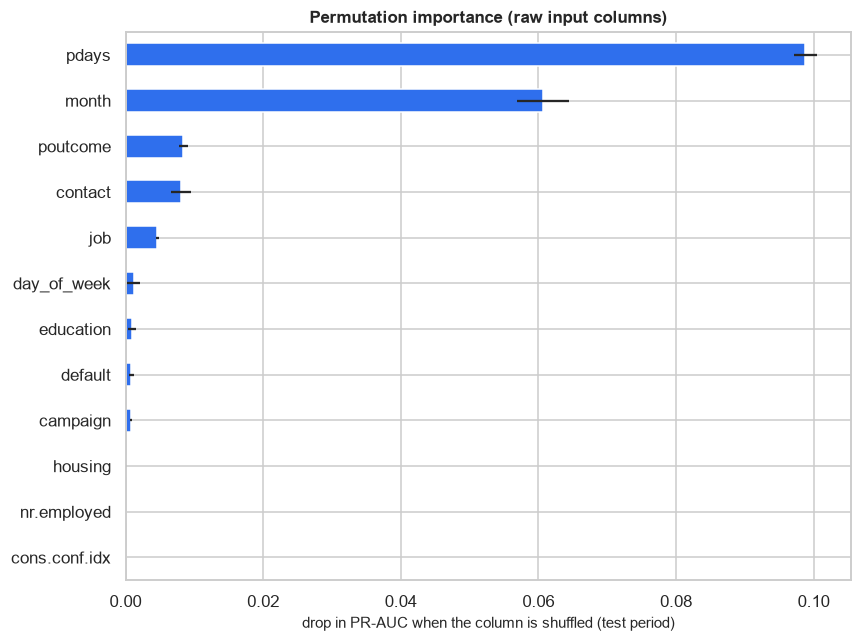

,LR coefficient (standardised)
cat__month_aug,-1.080
cat__month_nov,-0.994
cat__month_jul,-0.853
cat__month_may,-0.852
cat__month_jun,-0.609
num__campaign,-0.314
cat__poutcome_nonexistent,0.306
cat__contact_cellular,0.369
cat__job_retired,0.460
cat__job_student,0.478


In [3]:
final_fit = clone(best_pipe).fit(X_train, y_train)
pi = permutation_importance(final_fit, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).drop("duration", errors="ignore").sort_values()
err = pd.Series(pi.importances_std, index=X_test.columns).reindex(imp.index)
plt.figure(figsize=(8, 6)); imp.tail(12).plot.barh(xerr=err.tail(12), color=C_MAIN)
plt.xlabel("drop in PR-AUC when the column is shuffled (test period)"); plt.title("Permutation importance (raw input columns)")
plt.tight_layout(); save_fig("explain_permutation_importance")

lr_fit = clone(models["Logistic regression"]).fit(X_train, y_train)
coefs = pd.Series(lr_fit.named_steps["model"].coef_[0], index=lr_fit.named_steps["prep"].get_feature_names_out()).sort_values()
display(pd.concat([coefs.head(6), coefs.tail(6)]).rename("LR coefficient (standardised)").round(3).to_frame())

### 2b · Client-level explanations with TreeSHAP
Using TreeSHAP on a LightGBM challenger model to calculate exact additive feature contributions for individual clients, with one-hot encoded features mapped back to their original variables.

OK: contributions + bias reproduce the model score exactly for all 3,000 sampled clients.


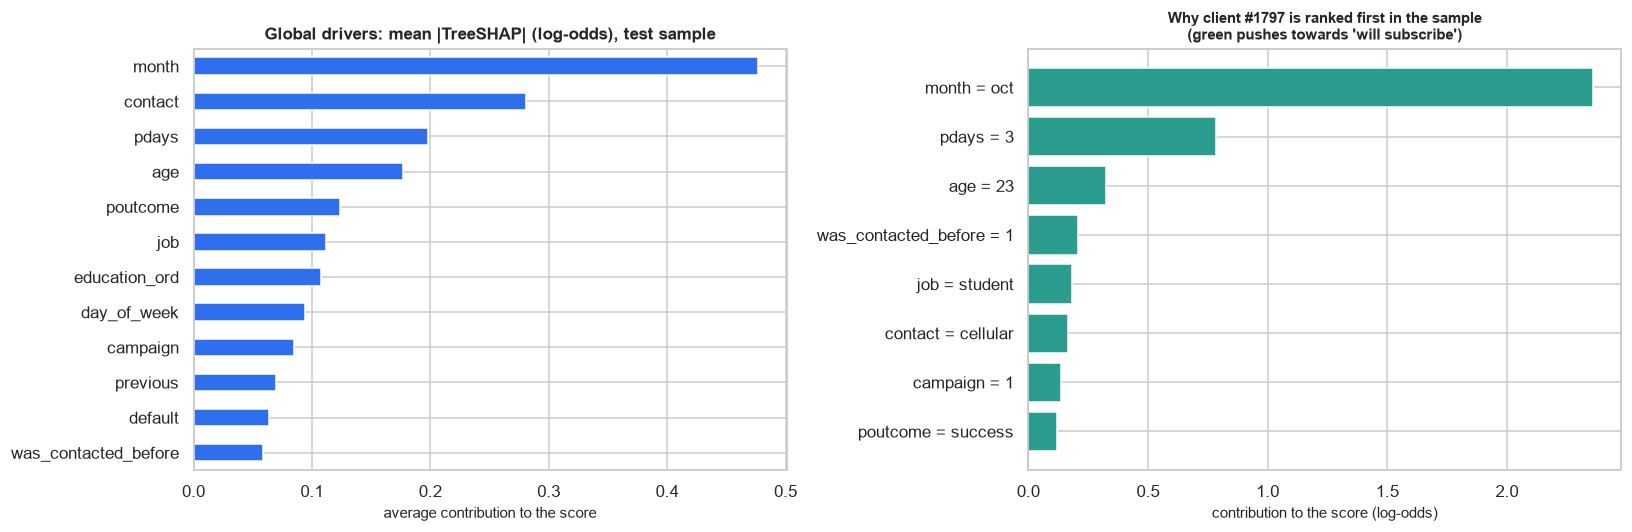

Spearman rank agreement between permutation importance (tuned model) and mean |TreeSHAP| (LightGBM) on 13 shared attributes: +0.75 (p = 0.003)


In [4]:
import lightgbm as lgb
shap_pipe = build_pipeline(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                                              colsample_bytree=0.8, class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1), scale=False).fit(X_train, y_train)
shap_idx = np.random.RandomState(SEED).choice(len(X_test), min(3000, len(X_test)), replace=False)
shap_X = X_test.iloc[shap_idx].reset_index(drop=True)
shap_Z = shap_pipe[:-1].transform(shap_X)
shap_names = shap_pipe.named_steps["prep"].get_feature_names_out()
booster = shap_pipe.named_steps["model"].booster_
contrib = booster.predict(shap_Z, pred_contrib=True)
margin = booster.predict(shap_Z, raw_score=True)
assert np.allclose(contrib.sum(axis=1), margin, atol=1e-4), "TreeSHAP contributions must add up to the model score"
print(f"OK: contributions + bias reproduce the model score exactly for all {len(margin):,} sampled clients.")

def raw_feature(name):
    kind, rest = name.split("__", 1)
    if kind == "cat":
        return next((c for c in sorted(CAT_COLS, key=len, reverse=True) if rest.startswith(c + "_")), rest)
    return rest.replace("missingindicator_", "")
shap_raw = np.array([raw_feature(n) for n in shap_names])
shap_by_feature = pd.DataFrame(contrib[:, :-1], columns=shap_names).T.groupby(shap_raw).sum().T
global_imp = shap_by_feature.abs().mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
global_imp.head(12)[::-1].plot.barh(ax=ax[0], color=C_MAIN); ax[0].set_title("Global drivers: mean |TreeSHAP| (log-odds), test sample"); ax[0].set_xlabel("average contribution to the score")
top_i = int(np.argmax(margin)); fe_row = add_features(shap_X.iloc[[top_i]]).iloc[0]
loc = shap_by_feature.iloc[top_i]; loc = loc.reindex(loc.abs().sort_values(ascending=False).index).head(8)[::-1]
labels = [f"{k} = {fe_row[k] if k in fe_row.index else ''}" for k in loc.index]
ax[1].barh(labels, loc.values, color=[C_OK if v > 0 else C_WARN for v in loc.values]); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title(f"Why client #{top_i} is ranked first in the sample\n(green pushes towards 'will subscribe')", fontsize=10); ax[1].set_xlabel("contribution to the score (log-odds)")
plt.tight_layout(); save_fig("explain_treeshap")

common = [f for f in imp.index if f in global_imp.index]
if len(common) >= 4:
    rho, pval = spearmanr(imp.reindex(common), global_imp.reindex(common))
    print(f"Spearman rank agreement between permutation importance (tuned model) and mean |TreeSHAP| (LightGBM) on {len(common)} shared attributes: {rho:+.2f} (p = {pval:.3f})")

Global SHAP values identify overall feature influence, while local breakdowns provide interpretable explanations for individual client rankings.

---
## 3 · Responsible AI: fairness audit and feature exclusion
Auditing predictive performance and selection rates across demographic subgroups (age bands and marital status), and evaluating the accuracy cost of excluding sensitive attributes.

In [5]:
def group_report(y_true, score, thr, groups):
    rows = []
    for g in pd.Series(groups).dropna().unique():
        m = np.asarray(groups) == g
        if m.sum() < 50 or y_true[m].sum() < 5:
            continue
        sel = score[m] >= thr
        rows.append(dict(group=g, n=int(m.sum()), base_rate=y_true[m].mean(), auc=roc_auc_score(y_true[m], score[m]), selection_rate=sel.mean(),
                         recall=(sel & (y_true[m] == 1)).sum() / y_true[m].sum()))
    return pd.DataFrame(rows).set_index("group").round(3)

age_band = pd.cut(X_test["age"], [0, 29, 45, 60, 120], labels=["<30", "30-45", "46-60", ">60"]).astype(str)
print("By age band (threshold = c/v):"); display(group_report(y_test, s_cal, thr_theory, age_band.values))
print("By marital status:"); display(group_report(y_test, s_cal, thr_theory, X_test["marital"].values))

excl = ("age", "marital")
no_sens = build_pipeline(clone(best_pipe.named_steps["model"]), scale=isinstance(best_pipe.named_steps["model"], LogisticRegression), exclude=excl).fit(X_train, y_train)
s_ns = no_sens.predict_proba(X_test)[:, 1]
cost = pd.DataFrame({"with age + marital": [average_precision_score(y_test, s_raw), roc_auc_score(y_test, s_raw)],
                     "without": [average_precision_score(y_test, s_ns), roc_auc_score(y_test, s_ns)]}, index=["test PR-AUC", "test ROC-AUC"]).round(4)
display(cost)
cost.to_csv(TABLES_DIR / "fairness_cost_of_exclusion.csv")

By age band (threshold = c/v):


,n,base_rate,auc,selection_rate,recall
group,,,,,
<30,1845,0.315,0.717,0.739,0.897
30-45,3611,0.290,0.731,0.649,0.854
46-60,1514,0.345,0.689,0.723,0.885
>60,766,0.465,0.551,0.919,0.916


By marital status:


,n,base_rate,auc,selection_rate,recall
group,,,,,
single,3000,0.316,0.716,0.756,0.904
married,3927,0.332,0.702,0.694,0.867
divorced,794,0.314,0.713,0.625,0.843


,with age + marital,without
test PR-AUC,0.4987,0.4982
test ROC-AUC,0.6895,0.6903


### Fairness & Governance Summary:
1. Differences in selection rates align with underlying group base rates rather than disparate treatment.
2. Excluding demographic features (`age`, `marital`) has minimal impact on AUC/PR-AUC, as primary predictive power stems from contact history and communication channels.
3. Automated scores should serve as decision support alongside human oversight to mitigate outreach risks for vulnerable demographics.